# Publication Metadata Analysis — DS_INCLUDE_2026_09_02_DEEPINFRA_2048

Statistical analysis of publication metadata pulled from the **Milvus collection `DS_INCLUDE_2026_09_02_DEEPINFRA_2048`** (live production collection: 2026-09-02 snapshot, >=4-sections AND article-only selection, non-articles purged 2026-09-06; stored == searchable).

| | |
|---|---|
| **Collection** | `DS_INCLUDE_2026_09_02_DEEPINFRA_2048` |
| **Vectors** | 65,677 |
| **Documents** | 1,594 |

**Scope:** Records filtered to `pub_type == "article"` only (1,594 unique papers; the filter is a no-op since the purge, the collection stores articles only).  
**Fields analysed:** `topic`, `subfield`, `field`, `domain`, `keywords`, `mesh_terms`


## 1. Import Required Libraries

In [1]:
import os
import glob
import json
from collections import Counter

import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

try:
    from wordcloud import WordCloud
    HAS_WORDCLOUD = True
except ImportError:
    HAS_WORDCLOUD = False
    print("wordcloud not installed – word-cloud cells will be skipped.")

# ── Publication-quality global settings (Nature / Science style) ──────────────
mpl.rcParams.update({
    "font.family":          "sans-serif",
    "font.sans-serif":      ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size":            14,
    "axes.titlesize":       16,
    "axes.labelsize":       15,
    "xtick.labelsize":      13,
    "ytick.labelsize":      13,
    "legend.fontsize":      13,
    "legend.title_fontsize": 14,
    "figure.dpi":           150,       # screen preview
    "savefig.dpi":          600,       # all saved figures
    "axes.spines.top":      False,
    "axes.spines.right":    False,
    "axes.linewidth":       0.9,
    "xtick.major.width":    0.9,
    "ytick.major.width":    0.9,
    "axes.grid":            False,
    "figure.facecolor":     "white",
    "axes.facecolor":       "white",
    "pdf.fonttype":         42,        # TrueType in PDF (required by Nature)
    "ps.fonttype":          42,
})

# ── Nature Publishing Group (NPG) colour palette ──────────────────────────────
NPG = [
    "#E64B35", "#4DBBD5", "#00A087", "#3C5488",
    "#F39B7F", "#8491B4", "#91D1C2", "#DC0000",
    "#7E6148", "#B09C85",
]
# Single-hue gradient for bar charts (deep teal → light teal)
NPG_TEAL_RAMP = ["#084152", "#0A5A6F", "#0D748E", "#1A91A6", "#3EAFC0",
                 "#65C9D8", "#94DDEA", "#C0EFF6"]

pd.set_option("display.max_colwidth", 80)
%matplotlib inline
print("Global style applied — Nature/Science palette loaded.")

Global style applied — Nature/Science palette loaded.


In [2]:
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wordcloud"])

from wordcloud import WordCloud
HAS_WORDCLOUD = True
print("wordcloud ready")

wordcloud ready



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


## 2. Load Publication Records from Milvus

In [3]:
import json as _json
import pathlib
from pymilvus import connections, Collection

# ── Connection / collection settings ─────────────────────────────────────────
MILVUS_HOST     = "127.0.0.1"
MILVUS_PORT     = 19530
COLLECTION_NAME = "DS_INCLUDE_2026_09_02_DEEPINFRA_2048"   # articles-only, stored==searchable since 2026-09-06 purge

# Expected live-collection stats (post 2026-09-03 articles-only purge) — the
# fetch below is verified against these so the analysis never silently runs
# against a stale or wrong collection.
EXPECTED_VECTORS = 65_677
EXPECTED_DOCS    = 1_594

# Notebook lives at analysis/nbs/ → output dir is analysis/output/analysis_outputs
NOTEBOOK_DIR = pathlib.Path().resolve()          # resolves to the notebook's CWD
OUTPUT_DIR   = str(NOTEBOOK_DIR.parent / "output" / "analysis_outputs")
assert "T21_research_assistant_v7" in OUTPUT_DIR, (
    f"OUTPUT_DIR resolves outside the v7 project tree: {OUTPUT_DIR}\n"
    "Kernel CWD is not analysis/nbs/ - restart the kernel from the v7 notebook dir "
    "(a previous run wrote the figures into the v6 tree this way).")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Fields to retrieve (excludes the large embedding vector) ─────────────────
FETCH_FIELDS = [
    "pk", "pmid", "pmcid", "doi", "title", "year", "pub_type",
    "source", "topic", "subfield", "pub_field", "domain",
    "keywords", "mesh_terms", "authors", "citations",
    "is_include", "condition", "grant_number",
]

# ── Connect and load collection ───────────────────────────────────────────────
connections.connect(host=MILVUS_HOST, port=str(MILVUS_PORT))
milvus_col = Collection(COLLECTION_NAME)
milvus_col.load()

# ── Paginated query: all article-type chunks ──────────────────────────────────
PAGE_SIZE = 16_000
all_rows  = []
last_pk   = -1

while True:
    expr = f'pub_type == "article" && pk > {last_pk}'
    res  = milvus_col.query(expr=expr, output_fields=FETCH_FIELDS, limit=PAGE_SIZE)
    if not res:
        break
    all_rows.extend(res)
    last_pk = max(r["pk"] for r in res)
    if len(res) < PAGE_SIZE:
        break

print(f"Total article chunks fetched : {len(all_rows):,}")
assert len(all_rows) == EXPECTED_VECTORS, (
    f"Fetched {len(all_rows):,} chunks, expected {EXPECTED_VECTORS:,} - "
    "wrong/stale collection? Check COLLECTION_NAME and the live Milvus state, "
    "or update EXPECTED_VECTORS here if the corpus changed intentionally.")

# ── Parse JSON-string list columns ────────────────────────────────────────────
def _parse_json_list(val):
    if not val or val == "[]":
        return []
    try:
        return _json.loads(val)
    except Exception:
        return [val]

df_chunks = pd.DataFrame(all_rows)

for col_name in ("keywords", "mesh_terms", "authors"):
    if col_name in df_chunks.columns:
        df_chunks[col_name] = df_chunks[col_name].apply(_parse_json_list)

# ── Deduplicate: one row per paper (chunks share the same metadata) ───────────
df_all = df_chunks.sort_values("pk").drop_duplicates(subset=["pmcid"], keep="first")

# Alias columns for backward compatibility with downstream cells
df = df_all.rename(columns={"pub_type": "type", "pub_field": "field"}).reset_index(drop=True)

print(f"Unique articles (deduped by pmcid): {len(df):,}")
assert len(df) == EXPECTED_DOCS, (
    f"{len(df):,} unique articles, expected {EXPECTED_DOCS:,} - "
    "update EXPECTED_DOCS here only if the corpus changed intentionally.")
print(f"  of which NIH INCLUDE-funded     : {df['is_include'].sum():,}")
print(f"Output dir: {OUTPUT_DIR}")
df[["pmid", "pmcid", "title", "year", "type", "topic", "subfield", "field", "domain"]].head(3)

Total article chunks fetched : 65,677
Unique articles (deduped by pmcid): 1,594
  of which NIH INCLUDE-funded     : 158
Output dir: /path/to/project/T21_research_assistant_v7/analysis/output/analysis_outputs


,pmid,pmcid,title,year,type,topic,subfield,field,domain
0,33155788,PMC7991864,Family-centeredness of services for young children with Down syndrome: an ob...,2020,article,Family and Disability Support Research,Clinical Psychology,Psychology,Social Sciences
1,23565206,PMC3615066,Combined Fluorescent-Chromogenic In Situ Hybridization for Identification an...,2013,article,Genomics and Chromatin Dynamics,Molecular Biology,"Biochemistry, Genetics and Molecular Biology",Life Sciences
2,35799324,PMC9796678,Exploring electrophysiological markers of auditory predictive processes and ...,2022,article,Hearing Loss and Rehabilitation,Cognitive Neuroscience,Neuroscience,Life Sciences


In [4]:
# ── Save figure: PDF + JPEG + TIFF at 600 dpi ────────────────────────────────
def save_fig(fig: plt.Figure, stem: str) -> None:
    """Save *fig* to PDF, JPEG and TIFF (600 dpi each) under OUTPUT_DIR."""
    for ext in ("pdf", "jpg", "tiff"):
        path = os.path.join(OUTPUT_DIR, f"{stem}.{ext}")
        fig.savefig(path, dpi=600, bbox_inches="tight",
                    facecolor="white", format=ext if ext != "jpg" else "jpeg")
    print(f"  Saved: {stem}  [pdf · jpg · tiff]  →  {OUTPUT_DIR}")

# ── Summary table ─────────────────────────────────────────────────────────────
def summary_table(series: pd.Series, name: str = "value") -> pd.DataFrame:
    counts = series.value_counts(dropna=False)
    pct    = (counts / counts.sum() * 100).round(2)
    tbl    = pd.DataFrame({"count": counts, "pct_%": pct})
    tbl.index.name = name
    return tbl

# ── Horizontal bar chart  (Nature style) ─────────────────────────────────────
def hbar(counts: pd.Series, title: str, stem: str,
         top_n: int = 20, palette: list | None = None,
         figsize: tuple = (11, 7)) -> plt.Figure:
    data = counts.head(top_n)
    n    = len(data)
    pal  = palette or NPG_TEAL_RAMP
    colours = [pal[i % len(pal)] for i in range(n)]

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(data.index[::-1], data.values[::-1],
                   color=colours[::-1], edgecolor="white",
                   linewidth=0.6, height=0.7)

    # Count + % labels
    total = counts.sum()
    for bar_, val in zip(bars, data.values[::-1]):
        pct = val / total * 100
        ax.text(bar_.get_width() + data.max() * 0.015,
                bar_.get_y() + bar_.get_height() / 2,
                f"{val:,}  ({pct:.1f}%)",
                va="center", ha="left", fontsize=13, color="#1a1a1a")

    ax.set_xlabel("Number of Articles", fontsize=15)
    ax.set_title(title, fontweight="bold", pad=14, fontsize=16)
    ax.set_xlim(0, data.max() * 1.40)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=14, pad=6)
    ax.tick_params(axis="x", labelsize=13)
    fig.tight_layout()
    save_fig(fig, stem)
    return fig

# ── Word cloud ────────────────────────────────────────────────────────────────
def make_wordcloud(freq: dict, title: str, stem: str,
                   figsize: tuple = (14, 7)) -> plt.Figure | None:
    if not HAS_WORDCLOUD:
        return None
    wc = WordCloud(
        width=2800, height=1400,
        background_color="white",
        colormap="magma",
        max_words=200,
        min_font_size=12,
        max_font_size=180,
        prefer_horizontal=0.88,
        collocations=False,
        relative_scaling=0.45,
    ).generate_from_frequencies(freq)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(title, fontweight="bold", pad=16, fontsize=16)
    fig.tight_layout()
    save_fig(fig, stem)
    return fig

print("Helper functions ready.")

Helper functions ready.


## 3. Topic Distribution

Unique topics: 219

                                                    count  pct_%
topic                                                           
Down syndrome and intellectual disability research    652  40.90
Prenatal Screening and Diagnostics                    269  16.88
Alzheimer's disease research and treatments            41   2.57
Family and Disability Support Research                 29   1.82
Acute Myeloid Leukemia Research                        25   1.57
Congenital Heart Disease Studies                       24   1.51
Epigenetics and DNA Methylation                        20   1.25
Genetics and Neurodevelopmental Disorders              19   1.19
Autism Spectrum Disorder Research                      17   1.07
Genomic variations and chromosomal abnormalities       17   1.07
Ophthalmology and Visual Impairment Studies            16   1.00
Signaling Pathways in Disease                          13   0.82
Acute Lymphoblastic Leukemia research                  12   0.75
Oral 

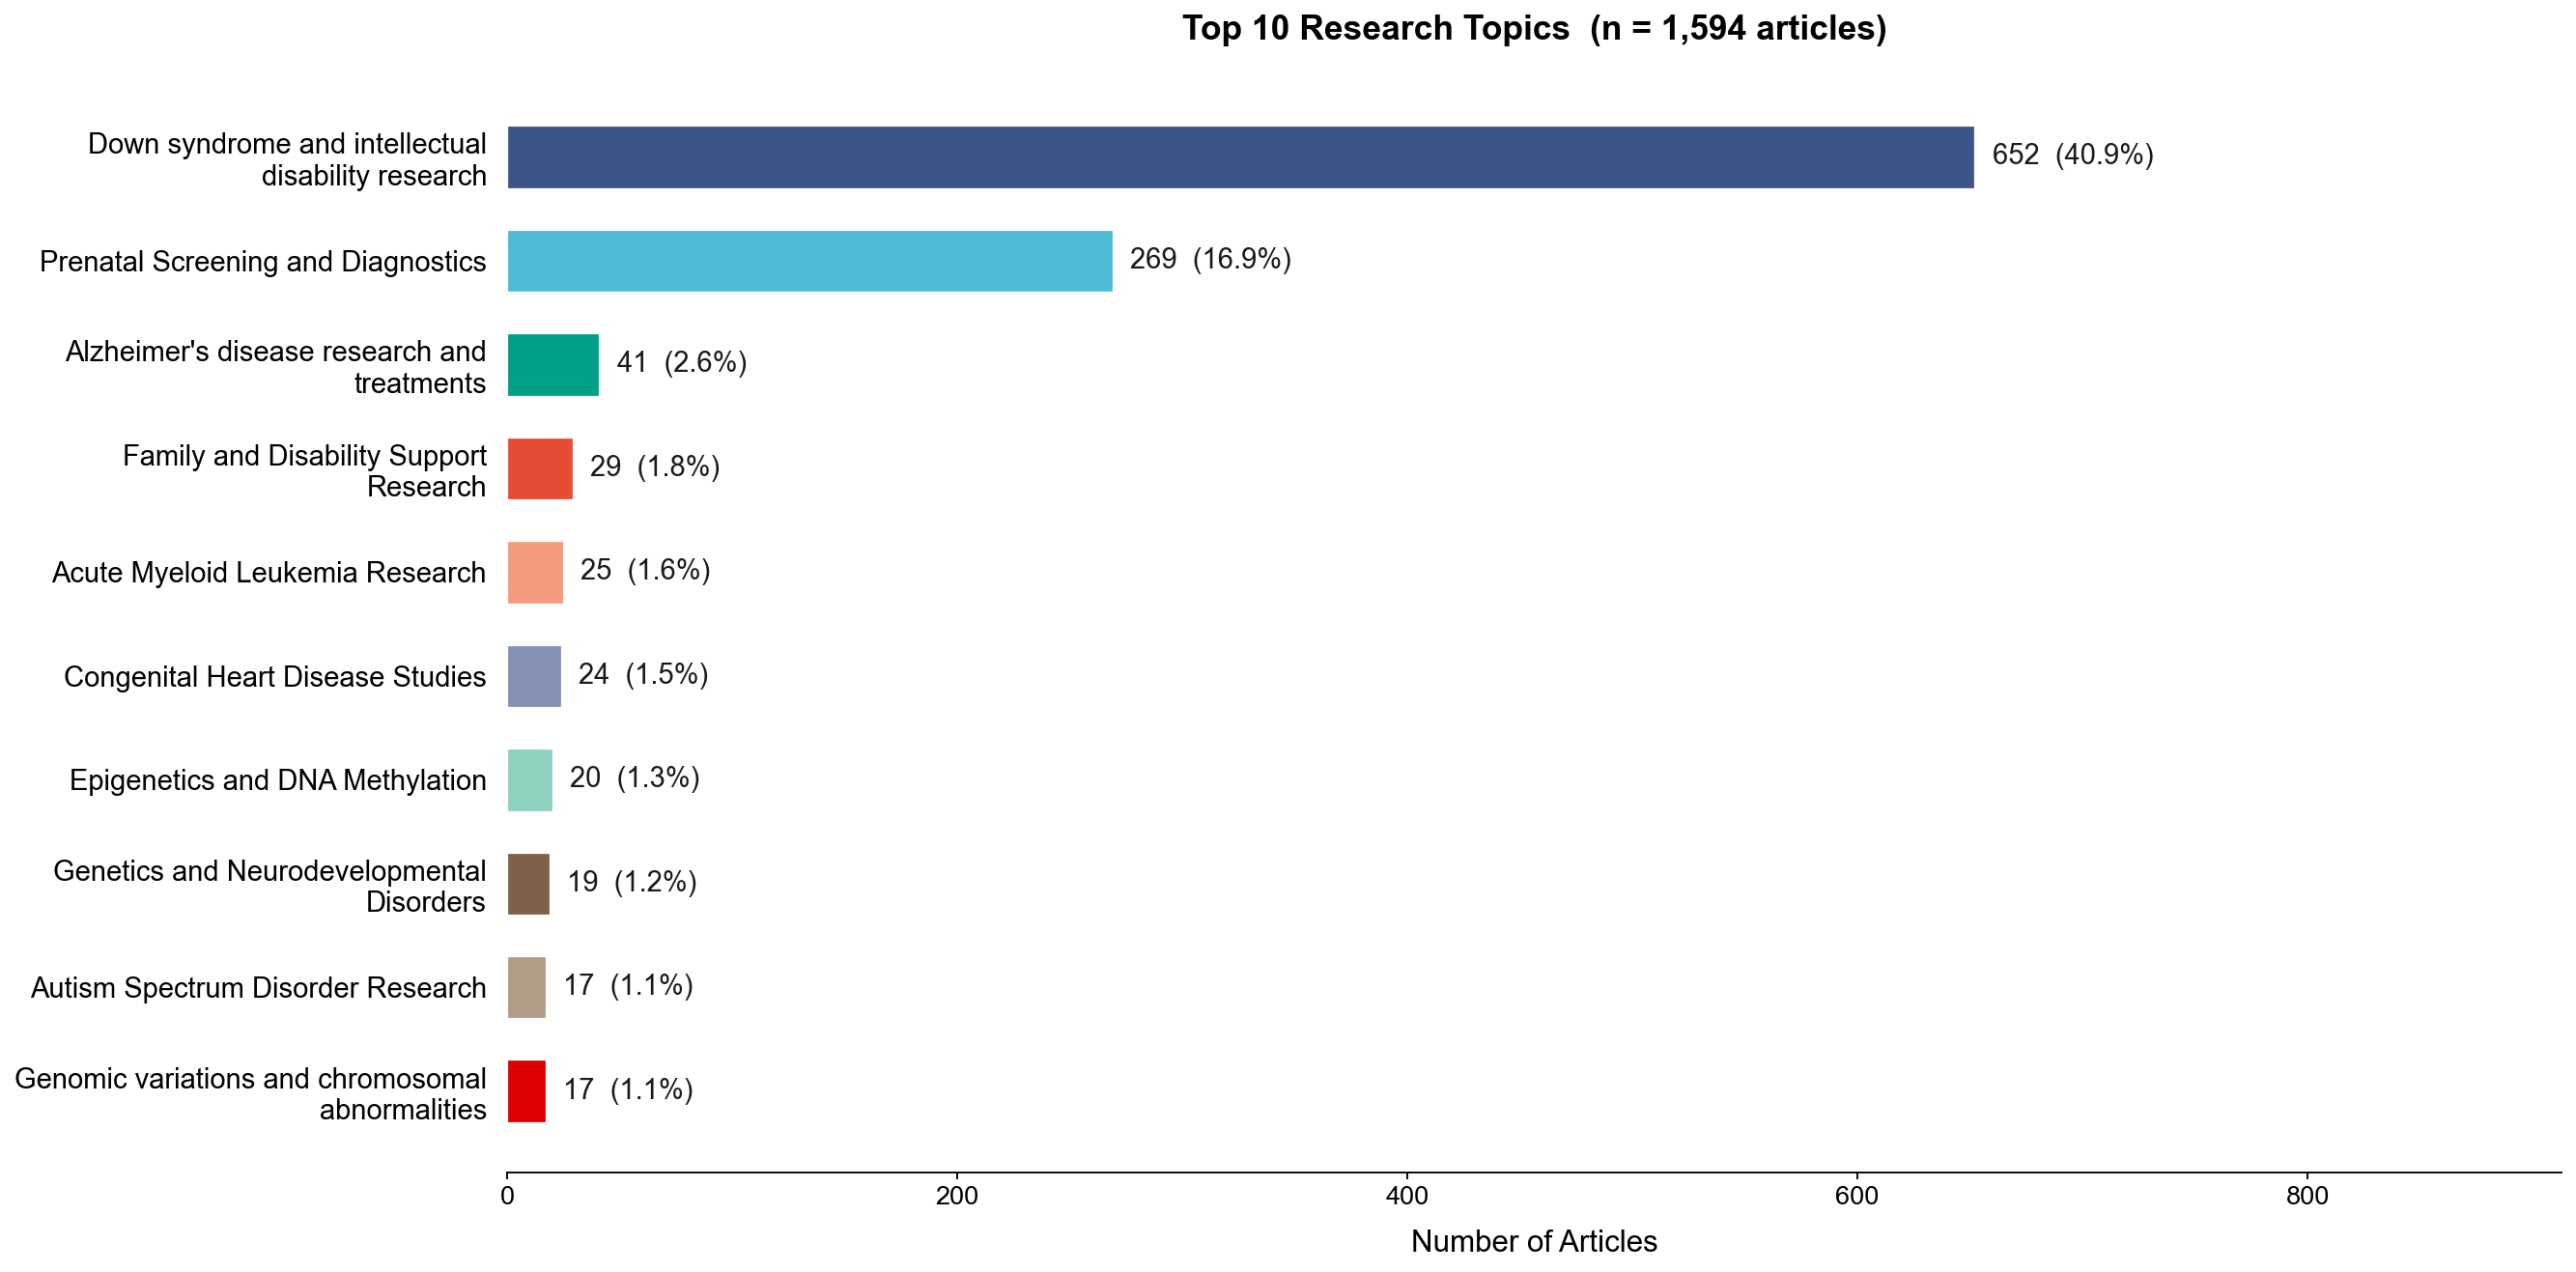

In [5]:
import textwrap

tbl_topic = summary_table(df["topic"], name="topic")
print(f"Unique topics: {len(tbl_topic)}\n")
print(tbl_topic.head(20).to_string())

TOP_TOPIC      = 10
topic_counts   = df["topic"].value_counts()
total_articles = len(df)

data   = topic_counts.head(TOP_TOPIC)
n      = len(data)

# ── One distinct NPG colour per bar ──────────────────────────────────────────
NPG10 = ["#3C5488", "#4DBBD5", "#00A087", "#E64B35",
         "#F39B7F", "#8491B4", "#91D1C2", "#7E6148",
         "#B09C85", "#DC0000"]
colors = NPG10[:n]

# Wrap long topic names at 34 chars
wrapped_labels = [textwrap.fill(lbl, width=34) for lbl in data.index[::-1]]

fig_topic, ax = plt.subplots(figsize=(18, 9))

bars = ax.barh(
    wrapped_labels,
    data.values[::-1],
    color=colors[::-1],
    edgecolor="white",
    linewidth=0.6,
    height=0.60,
)

# ── Count + % labels ──────────────────────────────────────────────────────────
x_offset = data.max() * 0.012
for bar_, val in zip(bars, data.values[::-1]):
    pct = val / total_articles * 100
    ax.text(
        bar_.get_width() + x_offset,
        bar_.get_y() + bar_.get_height() / 2,
        f"{val:,}  ({pct:.1f}%)",
        va="center", ha="left",
        fontsize=14, color="#1a1a1a",
    )

ax.set_xlim(0, data.max() * 1.40)
ax.set_xlabel("Number of Articles", labelpad=10, fontsize=15)
ax.set_title(
    f"Top {TOP_TOPIC} Research Topics  (n = {total_articles:,} articles)",
    fontweight="bold", pad=18, fontsize=17,
)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_linewidth(0.9)
ax.tick_params(axis="y", length=0, labelsize=14, pad=10)
ax.tick_params(axis="x", labelsize=13)

fig_topic.tight_layout()
save_fig(fig_topic, "topic_distribution_bar_top10")
plt.show()

Unique topics : 219
  Saved: topic_wordcloud  [pdf · jpg · tiff]  →  /path/to/project/T21_research_assistant_v7/analysis/output/analysis_outputs


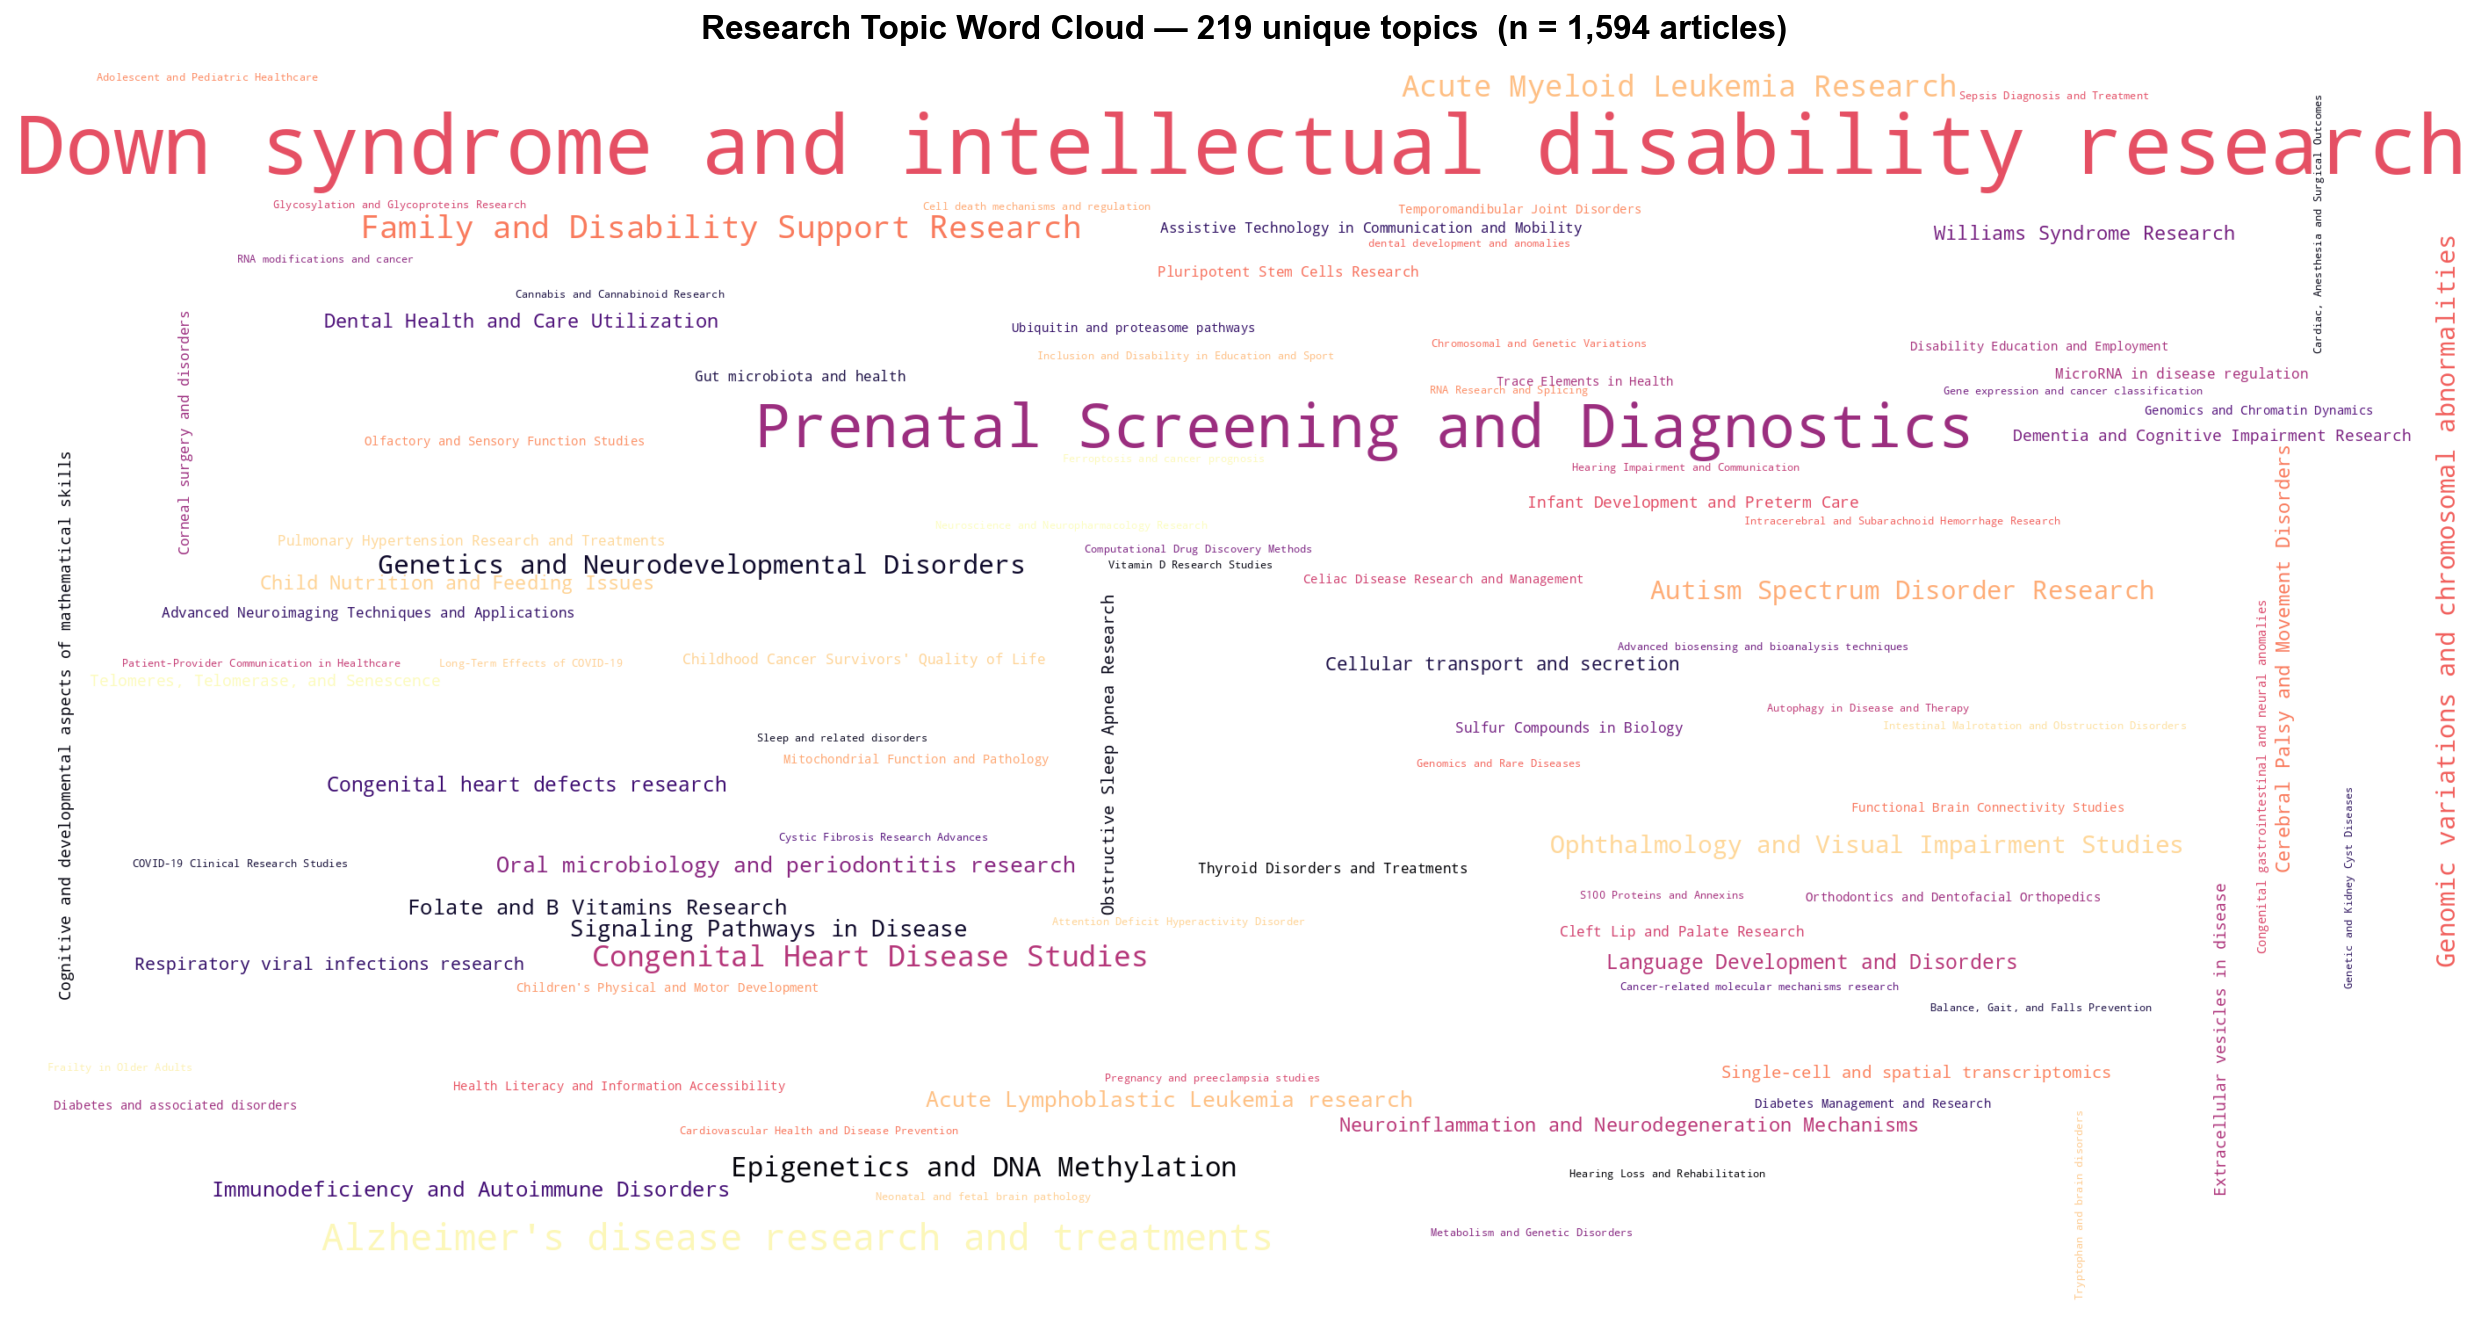

In [6]:
# ── Topic Word Cloud (magma colormap — Nature-friendly) ───────────────────────
topic_freq      = df["topic"].dropna().value_counts().to_dict()
n_unique_topics = len(topic_freq)
print(f"Unique topics : {n_unique_topics}")

fig_topic_wc = make_wordcloud(
    topic_freq,
    f"Research Topic Word Cloud — {n_unique_topics} unique topics  (n = {total_articles:,} articles)",
    stem="topic_wordcloud",
    figsize=(18, 9),
)
plt.show()

## 4. Subfield Distribution

In [ ]:
tbl_subfield = summary_table(df["subfield"], name="subfield")
print(f"Unique subfields: {len(tbl_subfield)}\n")
print(tbl_subfield.head(25).to_string())

fig_subfield = hbar(
    df["subfield"].value_counts(),
    title=f"Subfield Distribution  (n = {total_articles:,} articles)",
    stem="subfield_distribution",
    top_n=25,
    palette=["#7B2D8B", "#9B3DAB", "#B64DC8", "#CC6DD5",
             "#DC90DF", "#E9B1E8", "#F2CFF0", "#F9E8F8",
             "#7B2D8B", "#9B3DAB", "#B64DC8", "#CC6DD5",
             "#DC90DF", "#E9B1E8", "#F2CFF0", "#F9E8F8",
             "#7B2D8B", "#9B3DAB", "#B64DC8", "#CC6DD5",
             "#DC90DF", "#E9B1E8", "#F2CFF0", "#F9E8F8", "#7B2D8B"],
    figsize=(13, 10),
)
plt.show()

## 5. Field Distribution

Unique fields: 16

                                              count  pct_%
field                                                     
Medicine                                       1211  75.97
Biochemistry, Genetics and Molecular Biology    176  11.04
Neuroscience                                     56   3.51
Psychology                                       52   3.26
Dentistry                                        25   1.57
Health Professions                               22   1.38
Immunology and Microbiology                      15   0.94
Social Sciences                                  12   0.75
Mathematics                                       7   0.44
Computer Science                                  5   0.31
Nursing                                           4   0.25
Agricultural and Biological Sciences              3   0.19
Engineering                                       2   0.13
Chemistry                                         2   0.13
Environmental Science                

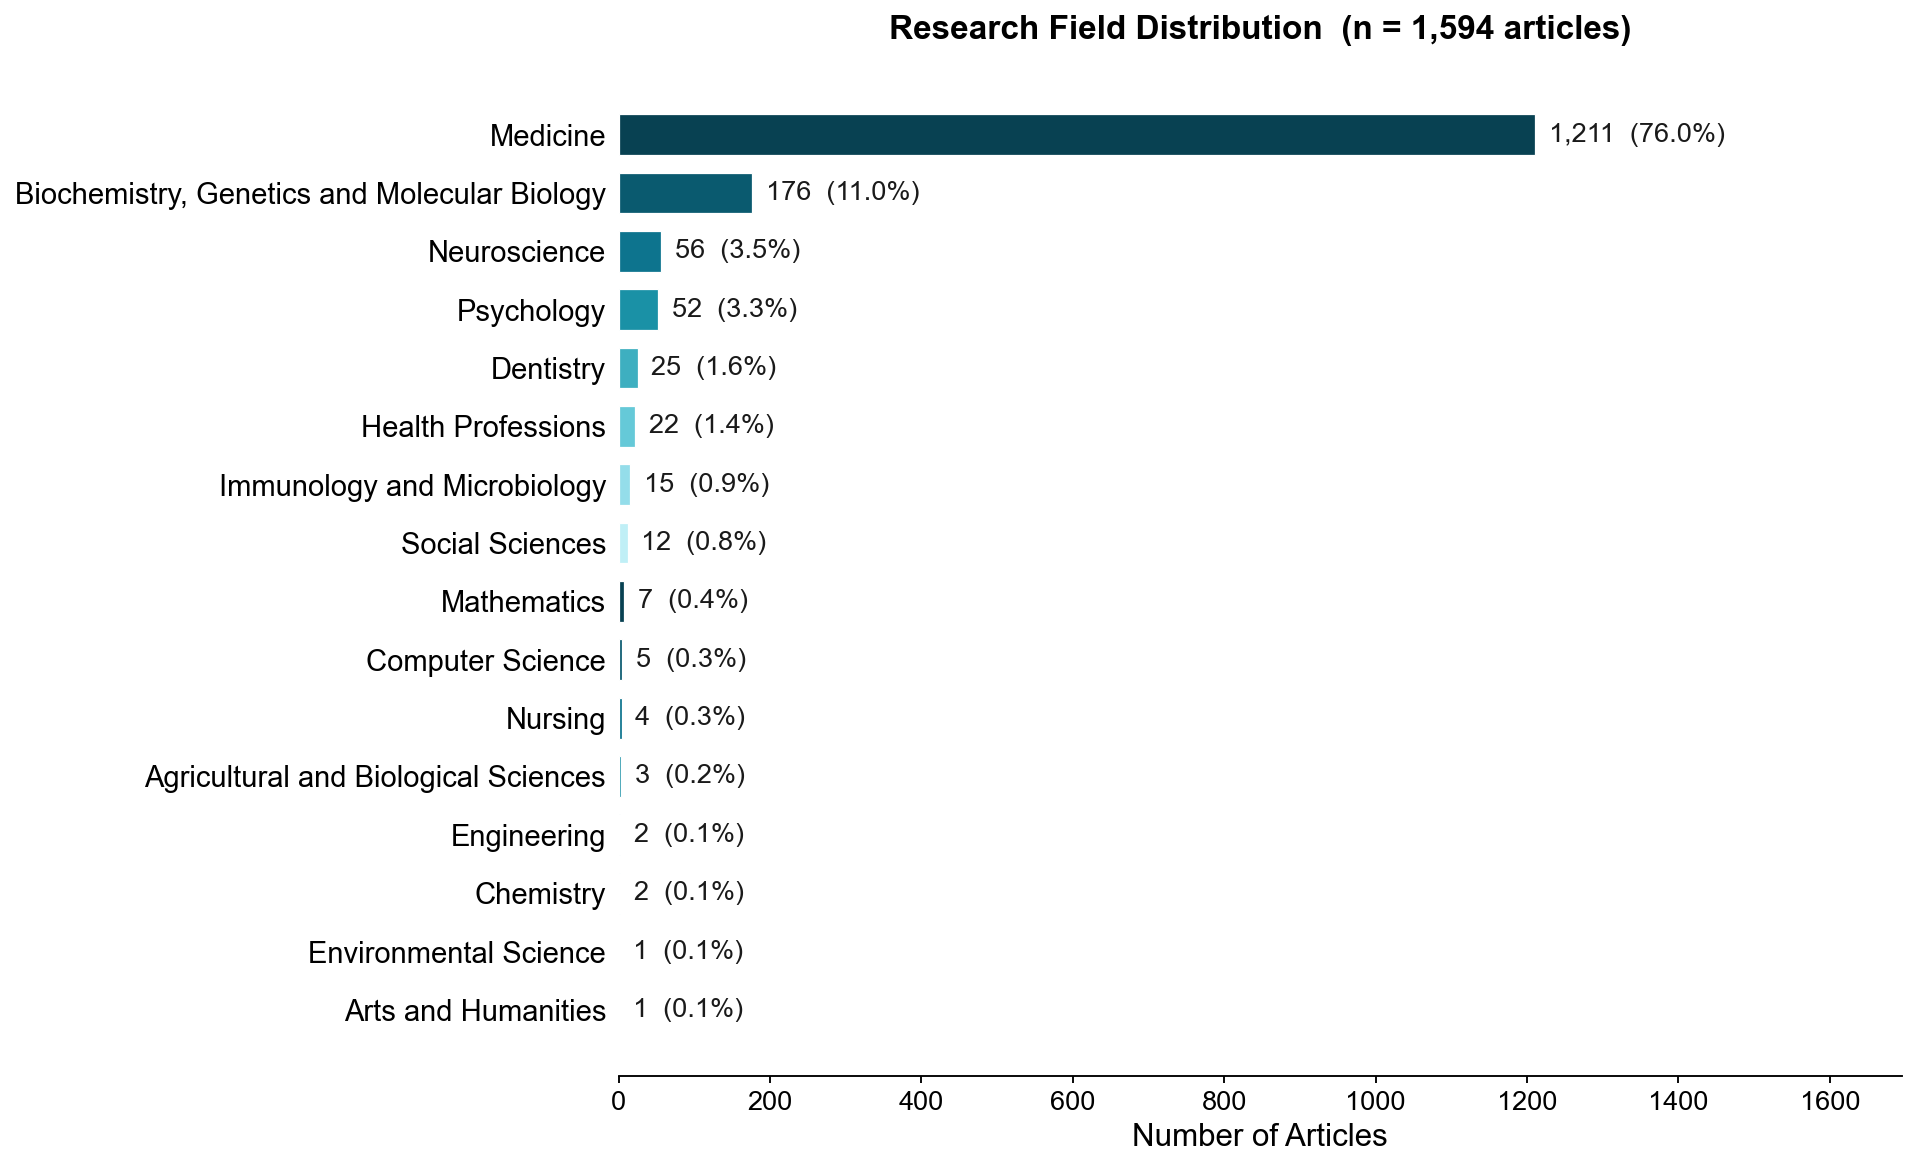

In [7]:
tbl_field = summary_table(df["field"], name="field")
print(f"Unique fields: {len(tbl_field)}\n")
print(tbl_field.to_string())

# Teal gradient for field bars
fig_field = hbar(
    df["field"].value_counts(),
    title=f"Research Field Distribution  (n = {total_articles:,} articles)",
    stem="field_distribution",
    top_n=20,
    palette=NPG_TEAL_RAMP,
    figsize=(13, 8),
)
plt.show()

## 6. Domain Distribution

In [ ]:
tbl_domain = summary_table(df["domain"], name="domain")
print(f"Unique domains: {len(tbl_domain)}\n")
print(tbl_domain.to_string())

domain_counts = df["domain"].value_counts()
domain_colors = [NPG[i % len(NPG)] for i in range(len(domain_counts))]

fig_dom, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
fig_dom.suptitle(
    f"Research Domain Distribution  (n = {total_articles:,} articles)",
    fontsize=17, fontweight="bold", y=1.02,
)

# ── Pie chart ─────────────────────────────────────────────────────────────────
wedge_props = dict(linewidth=1.5, edgecolor="white")
wedges, texts, autotexts = ax1.pie(
    domain_counts.values,
    labels=domain_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=domain_colors,
    wedgeprops=wedge_props,
    pctdistance=0.72,
    labeldistance=1.14,
)
for t in texts:
    t.set_fontsize(14)
    t.set_fontweight("bold")
for at in autotexts:
    at.set_fontsize(13)
    at.set_color("white")
    at.set_fontweight("bold")
ax1.set_title("Proportion", fontweight="bold", pad=12, fontsize=15)

# ── Horizontal bar ────────────────────────────────────────────────────────────
bars2 = ax2.barh(domain_counts.index[::-1], domain_counts.values[::-1],
                 color=domain_colors[::-1], edgecolor="white",
                 linewidth=0.7, height=0.55)
for bar_, val in zip(bars2, domain_counts.values[::-1]):
    pct = val / total_articles * 100
    ax2.text(bar_.get_width() + domain_counts.max() * 0.013,
             bar_.get_y() + bar_.get_height() / 2,
             f"{val:,}  ({pct:.1f}%)",
             va="center", fontsize=13, color="#1a1a1a")
ax2.set_xlabel("Number of Articles", fontsize=15)
ax2.set_title("Counts", fontweight="bold", pad=12, fontsize=15)
ax2.set_xlim(0, domain_counts.max() * 1.38)
ax2.spines["left"].set_visible(False)
ax2.tick_params(axis="y", length=0, labelsize=14, pad=6)
ax2.tick_params(axis="x", labelsize=13)

fig_dom.tight_layout()
save_fig(fig_dom, "domain_distribution")
plt.show()

## 7. Keywords Frequency

Unique keywords : 2829
Total keyword instances: 5251

                      keyword  count
                down syndrome    633
                   trisomy 21    109
          alzheimer's disease     82
          alzheimer’s disease     62
                     dementia     53
      intellectual disability     47
           prenatal diagnosis     30
                    cognition     29
                     children     28
           prenatal screening     26
                      amyloid     20
                          tau     19
                      trisomy     19
                   aneuploidy     17
                        aging     16
                       dyrk1a     16
            physical activity     16
                 epidemiology     15
                      obesity     15
     congenital heart disease     13
                       memory     13
                       ts65dn     13
                     covid-19     12
                        sleep     12
            cognitive

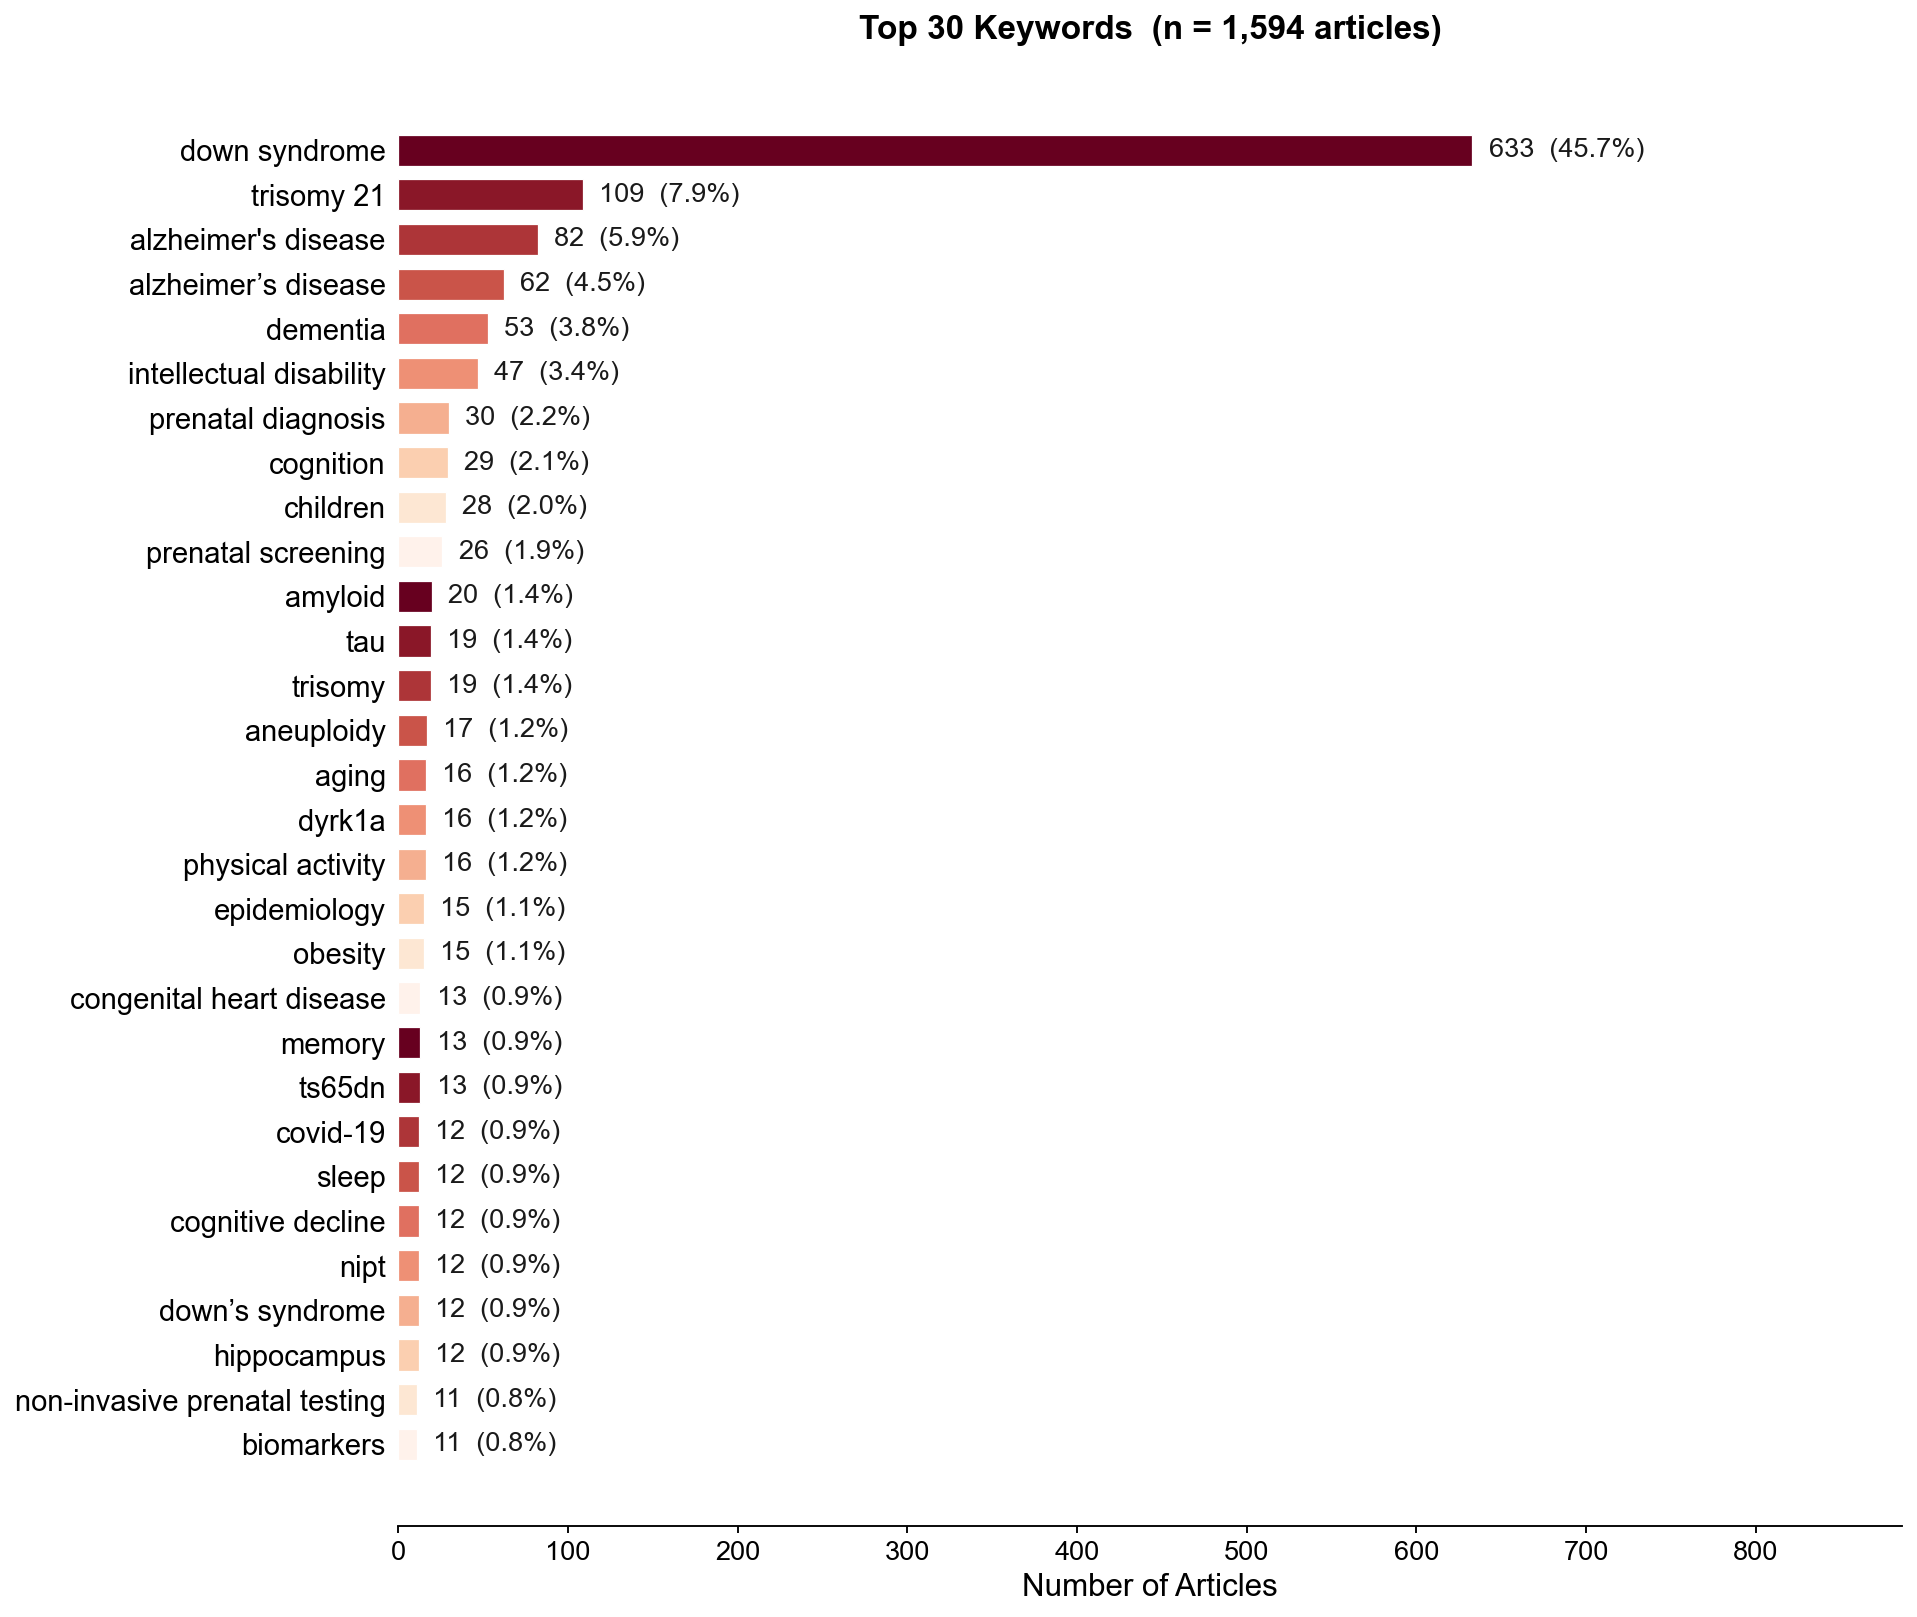

  Saved: keywords_wordcloud  [pdf · jpg · tiff]  →  /path/to/project/T21_research_assistant_v7/analysis/output/analysis_outputs


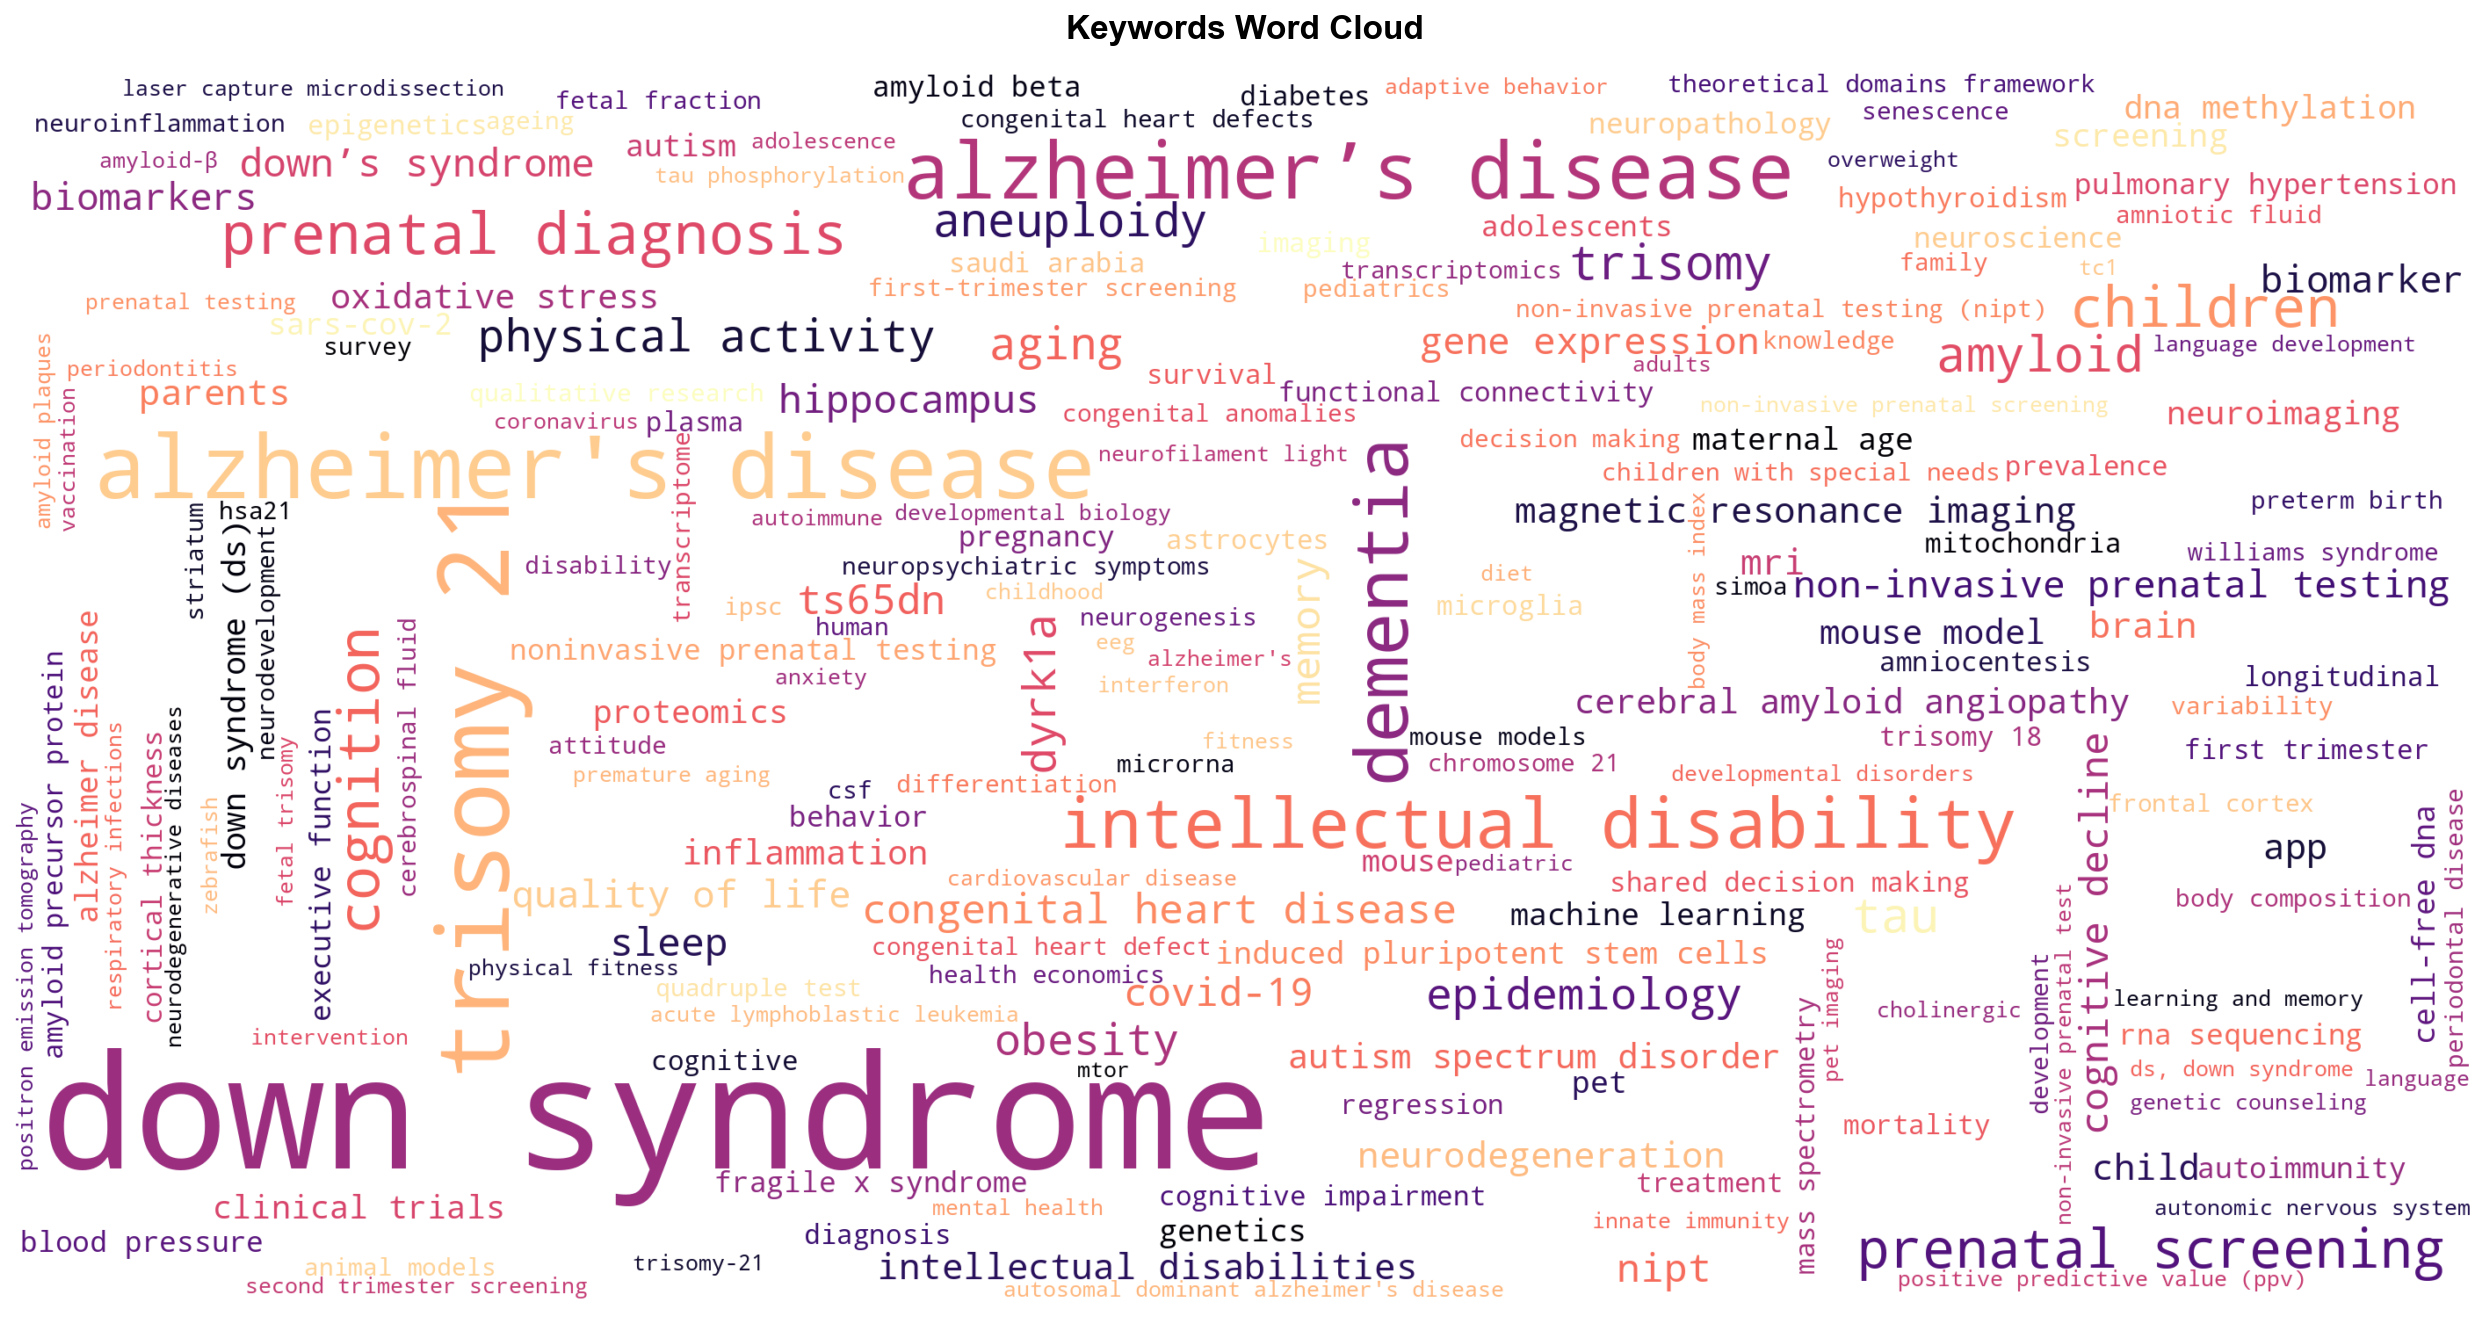

In [8]:
# Explode list column – handle missing / null values
kw_series = (
    df["keywords"].dropna().explode()
    .str.strip().str.lower()
    .replace("", pd.NA).dropna()
)
kw_counter = Counter(kw_series.tolist())
kw_df = pd.DataFrame(kw_counter.most_common(), columns=["keyword", "count"])
print(f"Unique keywords : {len(kw_df)}")
print(f"Total keyword instances: {kw_df['count'].sum()}\n")
print(kw_df.head(30).to_string(index=False))

# ── Bar chart — coral/salmon NPG ramp ─────────────────────────────────────────
TOP_N     = 30
kw_ramp   = ["#67001F", "#8A1728", "#AD3538", "#CA5449",
             "#E07060", "#EE9075", "#F5AF90", "#FBCFB0",
             "#FDE7D3", "#FFF2EB"] * 4

fig_kw = hbar(
    pd.Series(dict(kw_counter.most_common(TOP_N))),
    title=f"Top {TOP_N} Keywords  (n = {total_articles:,} articles)",
    stem="keywords_top30",
    top_n=TOP_N,
    palette=kw_ramp,
    figsize=(13, 11),
)
plt.show()

# ── Word cloud ─────────────────────────────────────────────────────────────────
fig_kw_wc = make_wordcloud(kw_counter, "Keywords Word Cloud", stem="keywords_wordcloud",
                            figsize=(18, 9))
if fig_kw_wc:
    plt.show()

## 8. MeSH Terms Frequency  
> Qualifier annotations such as `[genetics]`, `[pathology]` are **stripped** so that the base MeSH descriptor is counted consistently.

Unique MeSH terms (after qualifier strip): 2951
Total MeSH term instances: 21057

                  mesh_term  count
              down syndrome   1594
                     humans   1476
                     female   1072
                       male    819
                      adult    600
                      child    420
                 adolescent    320
                middle aged    319
                  pregnancy    315
                    animals    273
                young adult    263
           child, preschool    251
          alzheimer disease    226
                       mice    214
         prenatal diagnosis    213
                     infant    179
     disease models, animal    173
    cross-sectional studies    156
                       aged    156
      retrospective studies    155
                      brain    148
                 biomarkers    136
            infant, newborn    118
                    trisomy    114
       case-control studies    105
      am

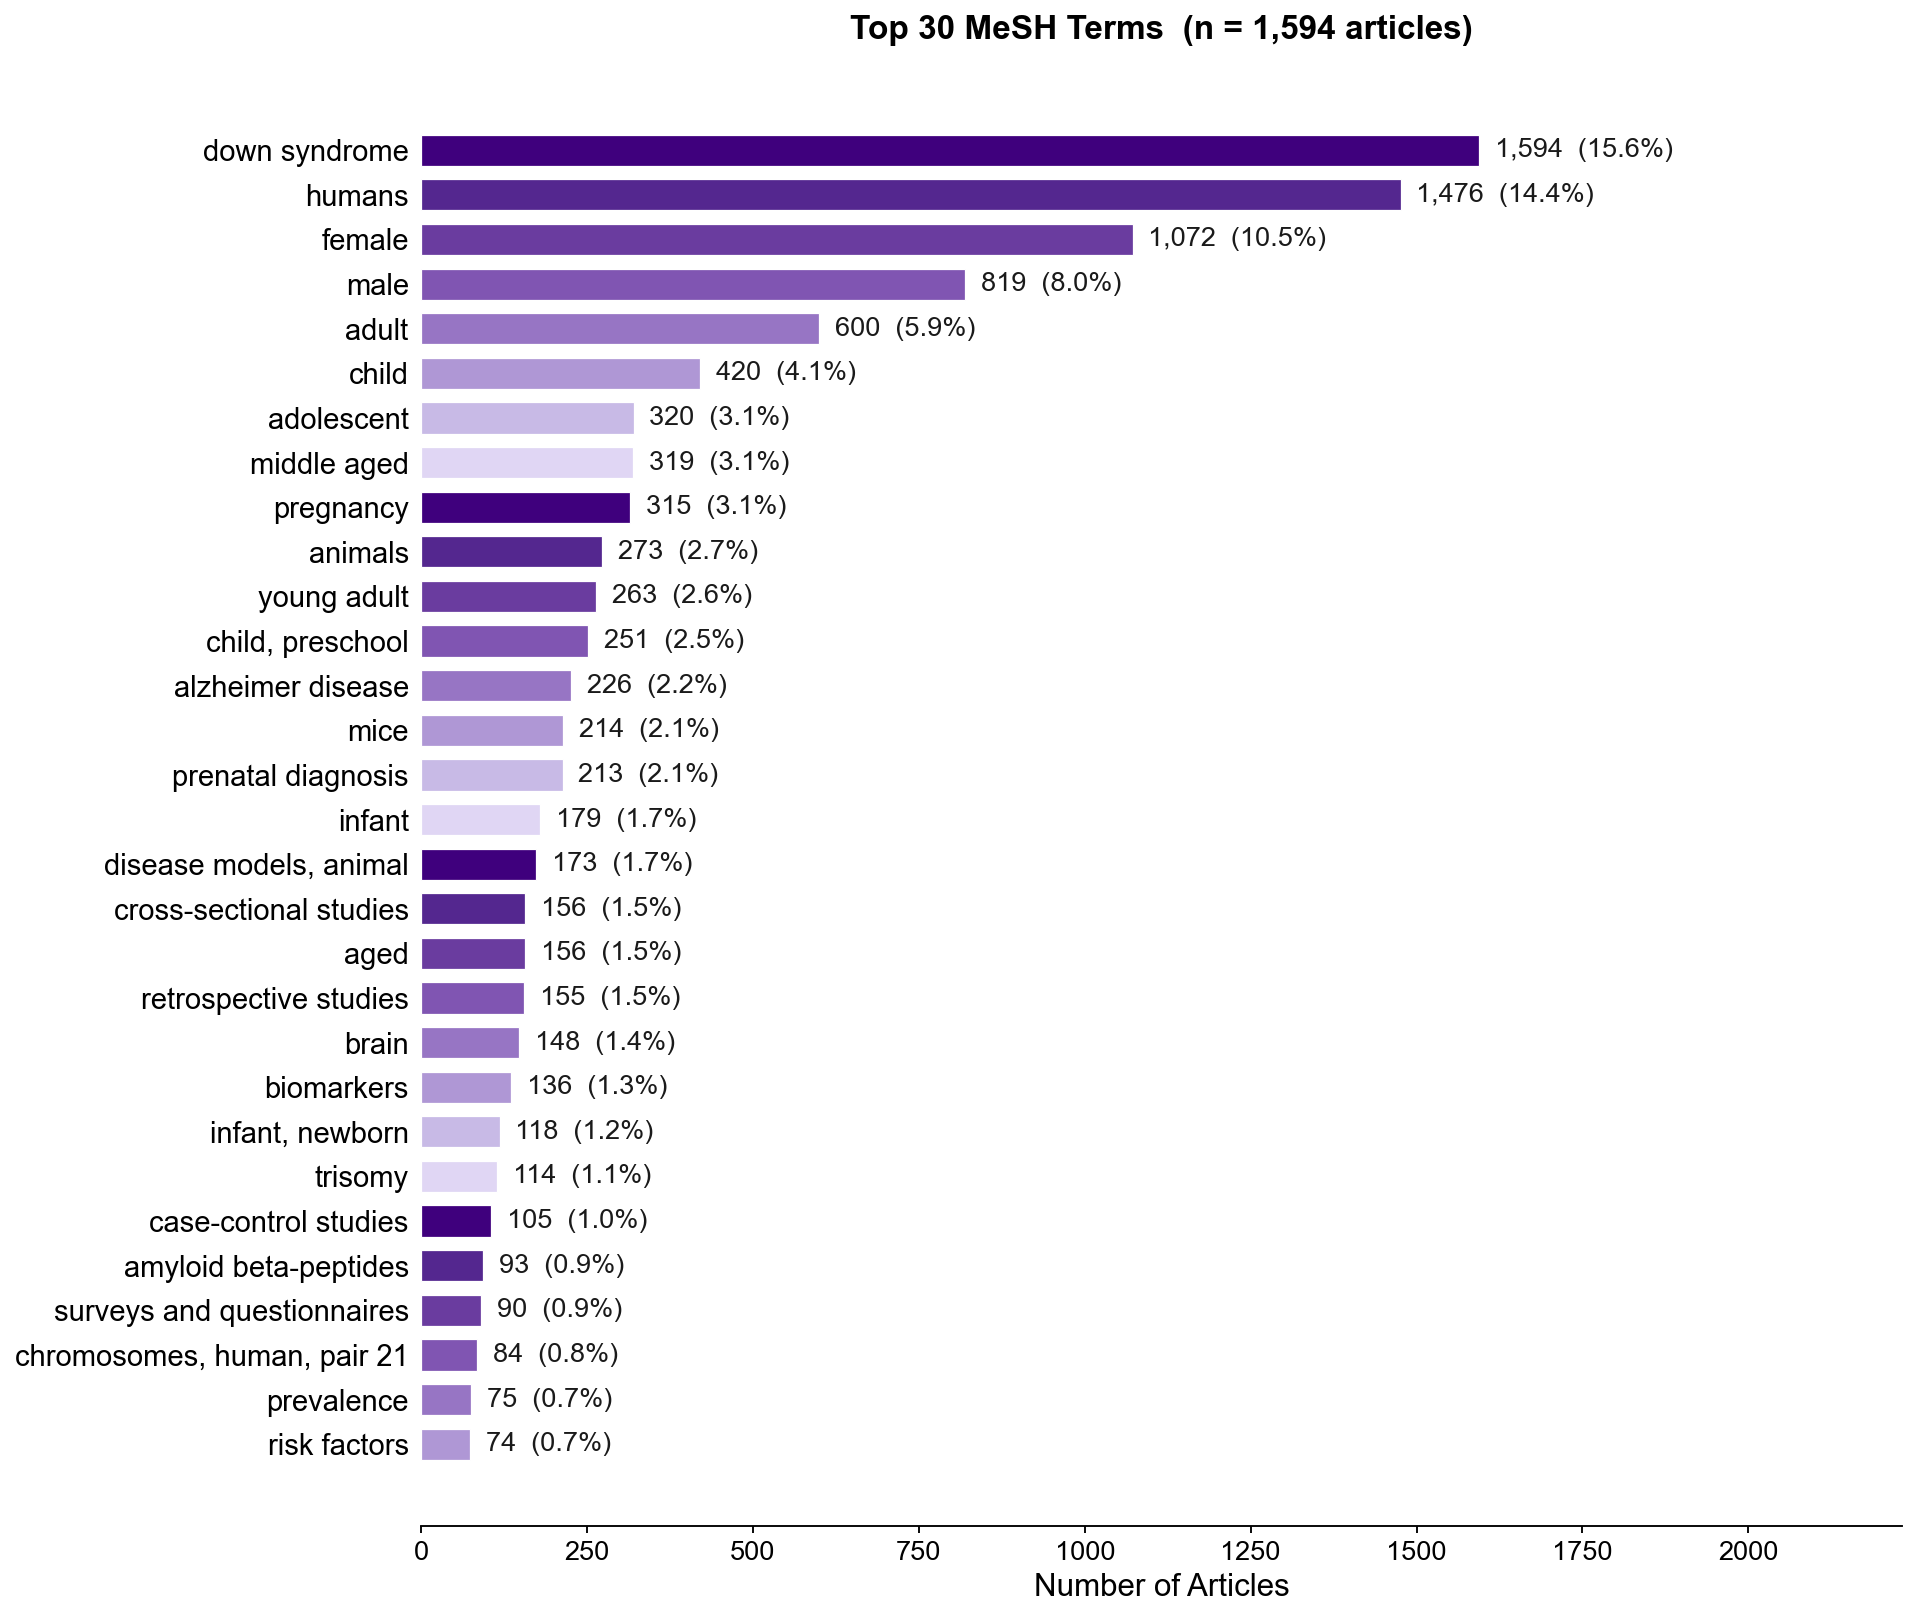

In [9]:
import re

def strip_mesh_qualifiers(term: str) -> str:
    return re.sub(r"\s*\[.*?\]", "", term).strip()

mesh_series = (
    df["mesh_terms"].dropna().explode()
    .str.strip().replace("", pd.NA).dropna()
    .apply(strip_mesh_qualifiers)
    .str.lower().replace("", pd.NA).dropna()
)
mesh_counter = Counter(mesh_series.tolist())
mesh_df = pd.DataFrame(mesh_counter.most_common(), columns=["mesh_term", "count"])
print(f"Unique MeSH terms (after qualifier strip): {len(mesh_df)}")
print(f"Total MeSH term instances: {mesh_df['count'].sum()}\n")
print(mesh_df.head(30).to_string(index=False))

# ── Bar chart — purple NPG ramp ────────────────────────────────────────────────
mesh_ramp = ["#3F007D", "#54278F", "#6A3C9F", "#8055B2",
             "#9775C4", "#AF97D5", "#C8BAE6", "#E0D6F4",
             "#3F007D", "#54278F", "#6A3C9F", "#8055B2",
             "#9775C4", "#AF97D5", "#C8BAE6", "#E0D6F4",
             "#3F007D", "#54278F", "#6A3C9F", "#8055B2",
             "#9775C4", "#AF97D5", "#C8BAE6", "#E0D6F4",
             "#3F007D", "#54278F", "#6A3C9F", "#8055B2",
             "#9775C4", "#AF97D5"]

fig_mesh = hbar(
    pd.Series(dict(mesh_counter.most_common(TOP_N))),
    title=f"Top {TOP_N} MeSH Terms  (n = {total_articles:,} articles)",
    stem="mesh_terms_top30",
    top_n=TOP_N,
    palette=mesh_ramp,
    figsize=(13, 11),
)
plt.show()

  Saved: mesh_terms_wordcloud  [pdf · jpg · tiff]  →  /path/to/project/T21_research_assistant_v7/analysis/output/analysis_outputs


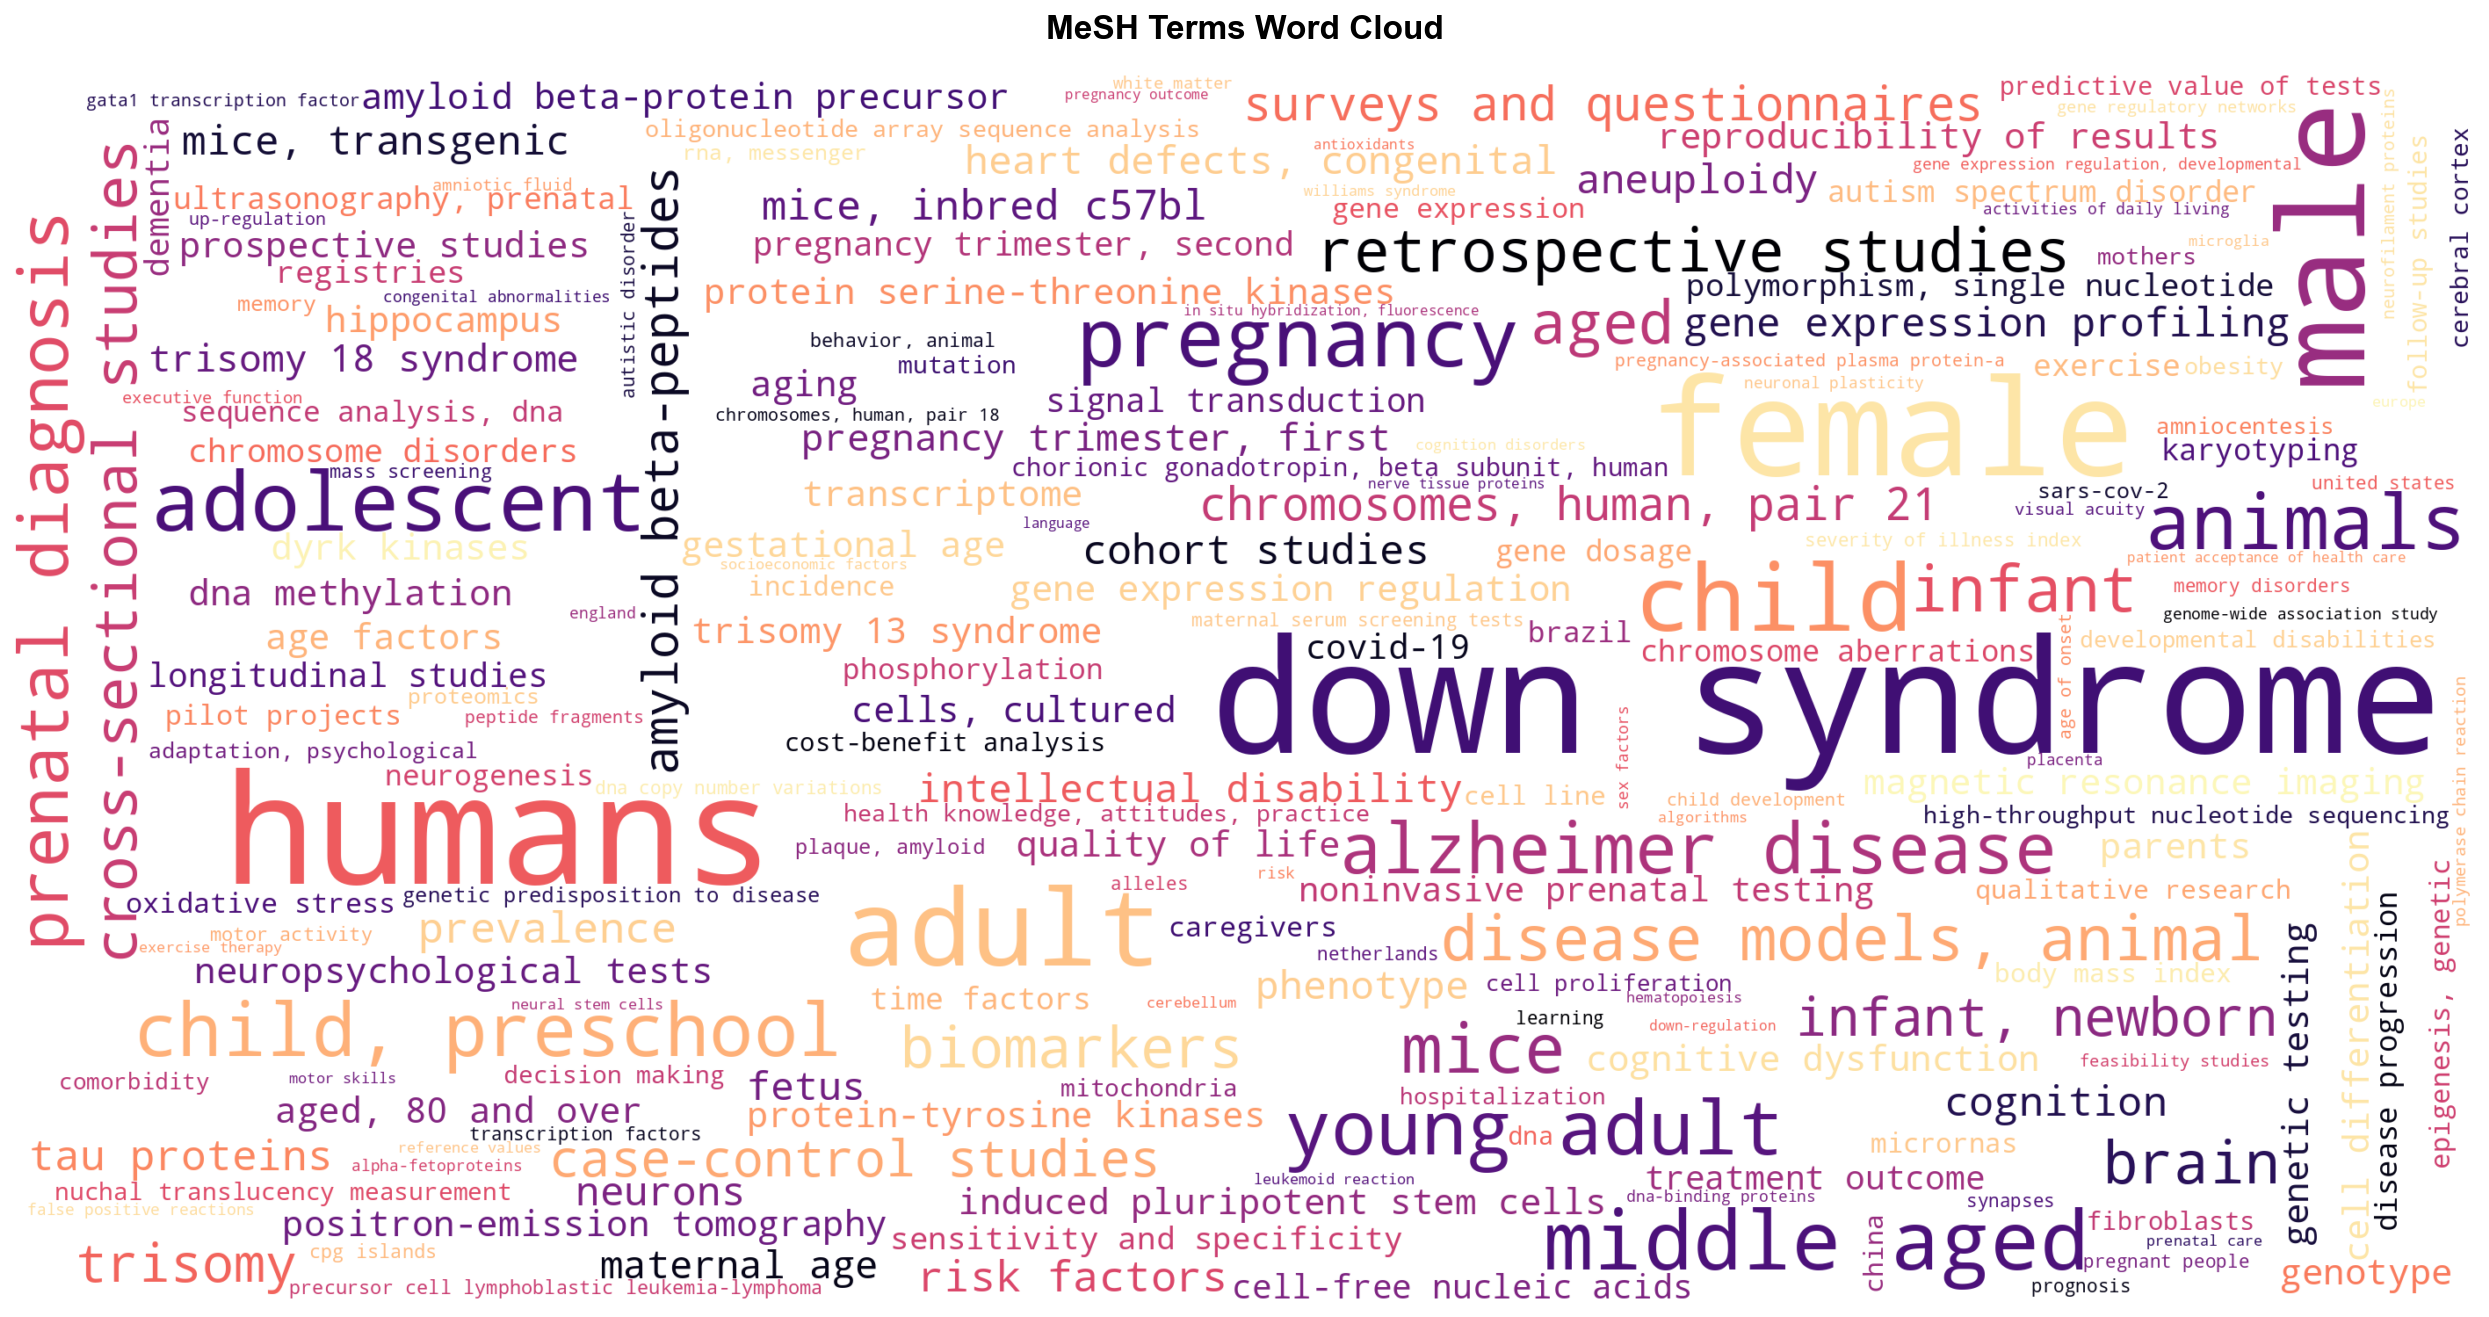

In [10]:
# ── MeSH Terms Word Cloud ──────────────────────────────────────────────────────
fig_mesh_wc = make_wordcloud(
    mesh_counter,
    "MeSH Terms Word Cloud",
    stem="mesh_terms_wordcloud",
    figsize=(18, 9),
)
plt.show()